# 07 · Cabin models: environmental gate and CO2 generator

**Questions**
1. **Environmental gate** (rules, not learned): replayed over the real ISS CO2 series, how often would it fire?
2. **CO2 generator** for the simulated crew: which of three candidates is closest to the real series?

**The gate** (thresholds from NASA OCHMO-TB-004): cabin CO2 is *high* when the 1-hour mean is above 3 mmHg or the 7-day mean is above 2.5 mmHg.
When CO2 is high **and** a crewmember reports headache or fatigue, the alert says *"likely environmental"* and the first suggestion is ventilation.

**Generator candidates:** A Gaussian + diurnal sinusoid · B AR(1) around the diurnal sinusoid · C block bootstrap of the real series.

**Inputs:** `data/processed/iss_cabin.parquet` (real, hourly, notebook 06); `data/processed/pmdata_daily.parquet` (real fatigue reports, for the symptom rate).
**Outputs:** figures `reports/figures/07_*.png`, cabin parameters in `models/engine_config.json`.

In [1]:
import sys
sys.path.insert(0, "../ml")
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sol_ml.nbutil import *
from sol_ml.detectors import cabin as gate
from sol_ml.detectors.radiation import count_events
from sol_ml.sim import co2 as co2_sim

rng = setup()
pd.set_option("display.width", 230); pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore")

hourly = pd.read_parquet(PROCESSED / "iss_cabin.parquet")
series = {m: g.set_index("hour").co2_mmhg for m, g in hourly.groupby("mission") if g.co2_mmhg.notna().sum() >= 24 * 20}
order = sorted(series, key=lambda m: series[m].index.min())
print(len(series), "missions with at least 20 days of ISS CO2:", order)

10 missions with at least 20 days of ISS CO2: ['RR-1', 'RR-3', 'RR-5', 'RR-6', 'RR-7', 'RR-9', 'RR-12', 'RR-19', 'RR-10', 'RR-23']


## 1. Replay the gate's CO2 rules over the real ISS series

In [2]:
rows, rolled = [], {}
for m in order:
    one = series[m].to_numpy()
    seven = gate.rolling_mean(one)
    rolled[m] = (one, seven)
    seen = np.isfinite(one)
    high_1h = np.nan_to_num(one) > gate.LIMIT_1H_MMHG
    high_7d = np.nan_to_num(seven) > gate.LIMIT_7D_MMHG
    high = gate.co2_high(one, seven)
    months = seen.sum() / 720
    runs = np.diff(np.flatnonzero(np.diff(np.concatenate([[0], high.astype(int), [0]]))))[::2] if high.any() else np.array([0])
    rows.append({"mission": m, "year": series[m].index.min().year, "days": round(seen.sum() / 24, 1), "mean_mmHg": np.nanmean(one),
                 "time_1h_above_3": high_1h[seen].mean(), "time_7d_above_2.5": high_7d[np.isfinite(seven)].mean() if np.isfinite(seven).any() else np.nan,
                 "time_co2_high": high[seen].mean(), "episodes_per_month_1h_rule": count_events(high_1h, gap_hours=6) / months,
                 "longest_high_run_days": runs.max() / 24})
replay = pd.DataFrame(rows).set_index("mission")
all_one = np.concatenate([rolled[m][0] for m in order]); all_seven = np.concatenate([rolled[m][1] for m in order])
seen = np.isfinite(all_one)
overall = {"time_1h_above_3": (np.nan_to_num(all_one) > 3)[seen].mean(), "time_7d_above_2.5": (np.nan_to_num(all_seven) > 2.5)[np.isfinite(all_seven)].mean(),
           "time_co2_high": gate.co2_high(all_one, all_seven)[seen].mean()}
print("all missions together:", {k: f"{v:.1%}" for k, v in overall.items()}, "| total days:", round(seen.sum() / 24))
replay.round(3)

all missions together: {'time_1h_above_3': '6.8%', 'time_7d_above_2.5': '26.3%', 'time_co2_high': '25.4%'} | total days: 468


,year,days,mean_mmHg,time_1h_above_3,time_7d_above_2.5,time_co2_high,episodes_per_month_1h_rule,longest_high_run_days
mission,,,,,,,,
RR-1,2014,42.0,2.430,0.089,0.454,0.437,6.422,12.500
RR-3,2016,50.0,2.820,0.368,0.728,0.706,7.200,25.208
RR-5,2017,66.8,1.855,0.000,0.000,0.000,0.000,0.000
RR-6,2017,61.1,2.220,0.005,0.137,0.121,2.947,4.167
RR-7,2018,76.8,2.658,0.119,0.558,0.562,4.691,22.917
RR-9,2018,35.0,2.297,0.002,0.460,0.417,0.856,14.542
RR-12,2019,41.0,2.038,0.000,0.000,0.000,0.000,0.000
RR-19,2019,35.5,1.947,0.000,0.000,0.000,0.000,0.000
RR-10,2020,26.6,1.599,0.000,0.000,0.000,0.000,0.000


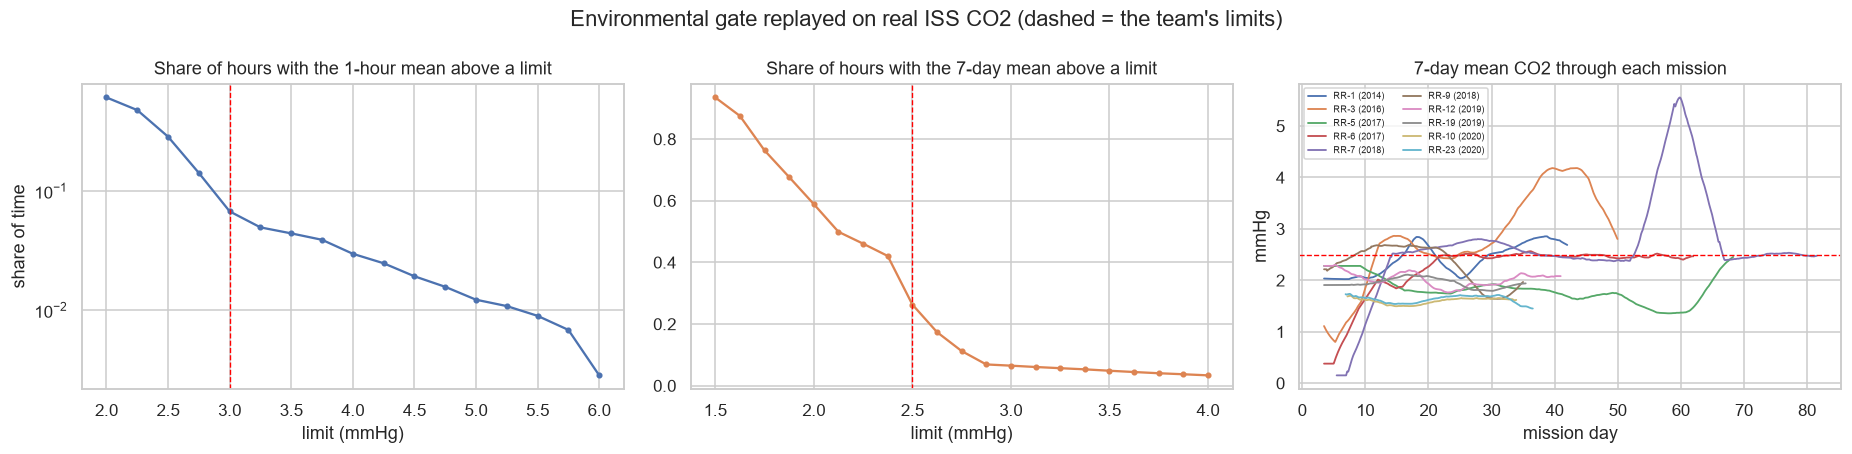

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
grid_1h, grid_7d = np.arange(2.0, 6.01, 0.25), np.arange(1.5, 4.01, 0.125)
axes[0].plot(grid_1h, [(np.nan_to_num(all_one) > t)[seen].mean() for t in grid_1h], marker="o", ms=3)
axes[0].axvline(gate.LIMIT_1H_MMHG, color="red", ls="--", lw=0.9)
axes[0].set(title="Share of hours with the 1-hour mean above a limit", xlabel="limit (mmHg)", ylabel="share of time", yscale="log")
ok7 = np.isfinite(all_seven)
axes[1].plot(grid_7d, [(all_seven[ok7] > t).mean() for t in grid_7d], marker="o", ms=3, color="#dd8452")
axes[1].axvline(gate.LIMIT_7D_MMHG, color="red", ls="--", lw=0.9)
axes[1].set(title="Share of hours with the 7-day mean above a limit", xlabel="limit (mmHg)")
for m in order:
    axes[2].plot(np.arange(len(rolled[m][1])) / 24, rolled[m][1], lw=1.2, label=f"{m} ({series[m].index.min().year})")
axes[2].axhline(gate.LIMIT_7D_MMHG, color="red", ls="--", lw=0.9)
axes[2].set(title="7-day mean CO2 through each mission", xlabel="mission day", ylabel="mmHg"); axes[2].legend(fontsize=6, ncol=2)
fig.suptitle("Environmental gate replayed on real ISS CO2 (dashed = the team's limits)")
savefig("07_gate_replay");

### How often would the full gate say "likely environmental"?
The gate also needs a symptom report. The ISS data has none, so the symptom rate comes from the real PMData self-reports:
a day counts as a "fatigue report" when the fatigue score is 2 or lower (worse than the usual 3; in PMSys a lower score is worse).
Assuming the reports are independent of cabin CO2 (true for people on Earth), the gate fires on `P(CO2 high) × P(report)` of person-days.
This is an estimate from two real datasets joined by an assumption, not a measurement.

In [4]:
pm = pd.read_parquet(PROCESSED / "pmdata_daily.parquet")
pm = pm[~pm.person.isin(["p12", "p13"]) & pm.fatigue.notna()]
report_rate = (pm.fatigue <= 2).groupby(pm.person).mean()
day_high = pd.concat([pd.Series(gate.co2_high(*rolled[m]), index=series[m].index).resample("D").max() for m in order])
p_high_day = float(day_high.mean())
print("fatigue-report days per person: median %.0f %%, range %.0f-%.0f %%" % (100 * report_rate.median(), 100 * report_rate.min(), 100 * report_rate.max()))
print("ISS days with CO2 high at some hour: %.0f %%" % (100 * p_high_day))
est = pd.DataFrame({"era": ["all missions", "2014-2019 missions", "2020-2021 missions"],
                    "P(CO2 high on a day)": [p_high_day, float(day_high[day_high.index.year <= 2019].mean()), float(day_high[day_high.index.year >= 2020].mean())]})
est["'likely environmental' days per person-month"] = est["P(CO2 high on a day)"] * report_rate.median() * 30
est["share of fatigue reports the gate would re-label"] = est["P(CO2 high on a day)"]
est.round(2)

fatigue-report days per person: median 30 %, range 2-74 %
ISS days with CO2 high at some hour: 29 %


,era,P(CO2 high on a day),'likely environmental' days per person-month,share of fatigue reports the gate would re-label
0,all missions,0.29,2.61,0.29
1,2014-2019 missions,0.34,3.15,0.34
2,2020-2021 missions,0.00,0.00,0.00


## 2. CO2 generator: which candidate is closest to the real series?
Each generator is fitted to one real mission and asked for a series of the same length, 20 times with different seeds. Scores (lower = closer):
KS distance of the value distribution, RMSE of the autocorrelation over 48 hours, RMSE of the mean-by-hour profile,
and the error in the share of hours above 3 mmHg (the number the gate depends on).

In [5]:
N_SEEDS = 20
rows = []
for m in order:
    real = series[m].interpolate(limit=6).to_numpy()
    real_clean = real[np.isfinite(real)]
    for name, gen in co2_sim.GENERATORS.items():
        for seed in range(N_SEEDS):
            sim = gen(real, n=len(real_clean), rng=np.random.default_rng(SEED + seed))
            s = co2_sim.similarity(real, sim)
            rows.append({"mission": m, "generator": name, **s,
                         "exceed_error": abs((sim > 3).mean() - (real_clean > 3).mean()),
                         "sd_ratio": sim.std() / real_clean.std()})
scores = pd.DataFrame(rows)
LABEL = {"gaussian_diurnal": "A Gaussian + diurnal", "ar1": "B AR(1) + diurnal", "block_bootstrap": "C block bootstrap"}
scores["generator"] = scores.generator.map(LABEL)
METRICS = ["ks", "acf_rmse", "diurnal_rmse", "exceed_error"]
per_mission = scores.groupby(["mission", "generator"])[METRICS].mean()
ranks = per_mission.groupby("mission").rank().groupby("generator").mean()
table = scores.groupby("generator")[METRICS + ["sd_ratio"]].mean().join(ranks.mean(axis=1).rename("mean_rank")).sort_values("mean_rank")
wins = per_mission.groupby("mission").idxmin().apply(lambda col: col.map(lambda t: t[1])).apply(pd.Series.value_counts).fillna(0).astype(int)
print("missions won per metric (of %d):" % len(order)); print(wins.to_string(), "\n")
table.round(3)

missions won per metric (of 10):
                      ks  acf_rmse  diurnal_rmse  exceed_error
A Gaussian + diurnal   2         0             0             5
B AR(1) + diurnal      0         7             1             0
C block bootstrap      8         3             9             5 



,ks,acf_rmse,diurnal_rmse,exceed_error,sd_ratio,mean_rank
generator,,,,,,
C block bootstrap,0.094,0.236,0.023,0.018,0.961,1.375
B AR(1) + diurnal,0.196,0.140,0.092,0.064,0.948,2.150
A Gaussian + diurnal,0.143,0.592,0.126,0.049,0.993,2.475


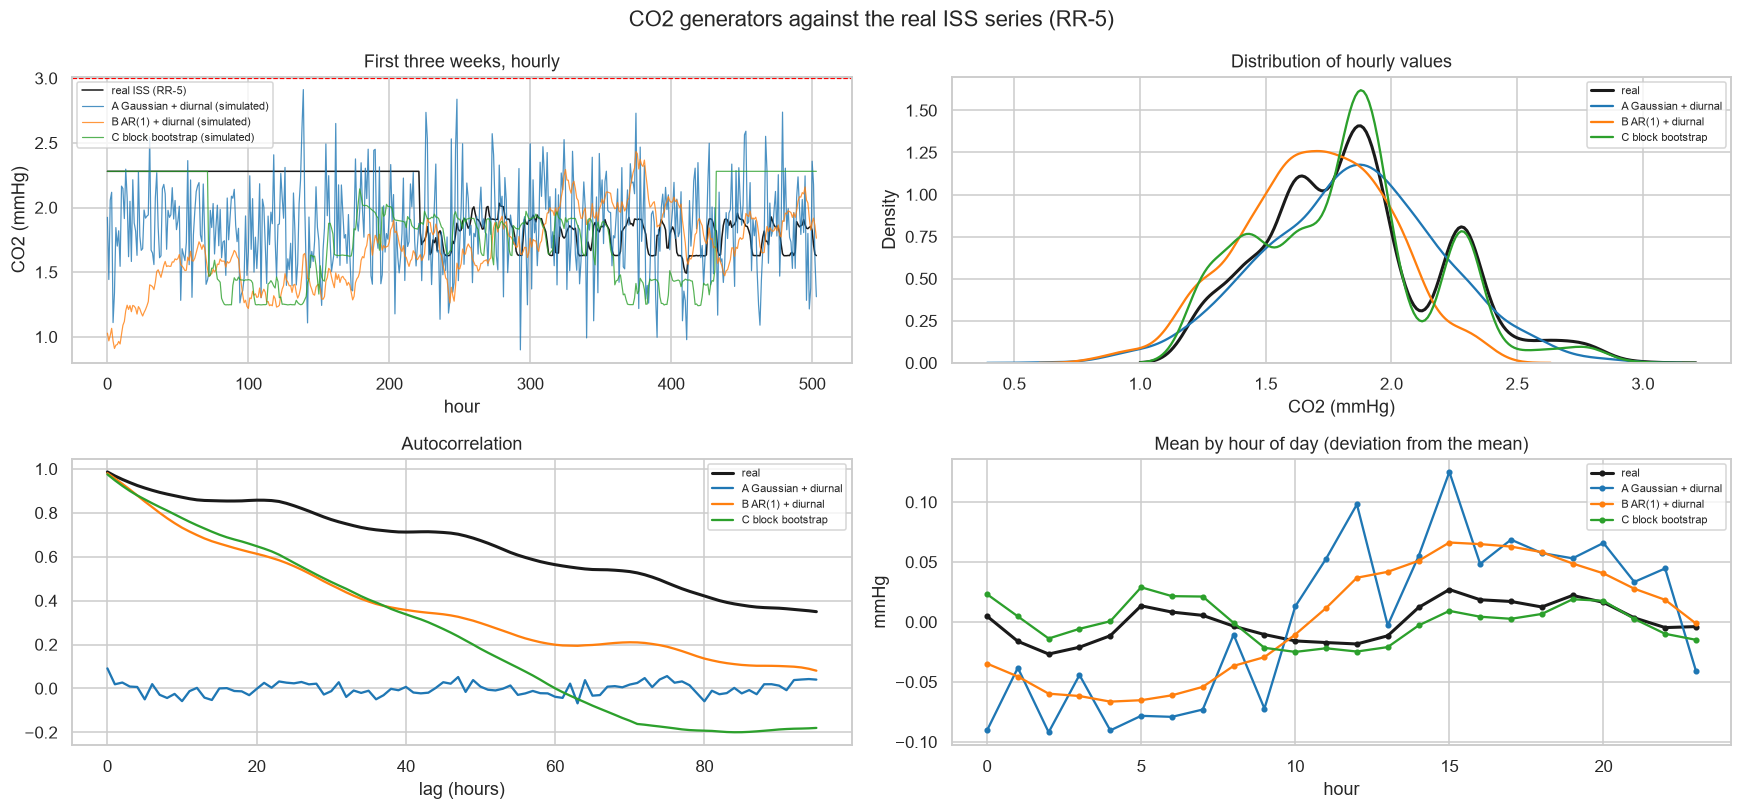

In [6]:
m = "RR-5"
real = series[m].interpolate(limit=6).to_numpy(); real_clean = real[np.isfinite(real)]
sims = {LABEL[k]: g(real, n=len(real_clean), rng=np.random.default_rng(SEED)) for k, g in co2_sim.GENERATORS.items()}
fig, axes = plt.subplots(2, 2, figsize=(16, 7.5))
ax = axes[0, 0]
ax.plot(real_clean[:24 * 21], color="k", lw=1, label="real ISS (RR-5)")
for (name, sim), color in zip(sims.items(), sns.color_palette("tab10", 3)):
    ax.plot(sim[:24 * 21], lw=0.8, alpha=0.8, color=color, label=name + " (simulated)")
ax.axhline(3, color="red", ls="--", lw=0.8); ax.set(title="First three weeks, hourly", xlabel="hour", ylabel="CO2 (mmHg)"); ax.legend(fontsize=7)
ax = axes[0, 1]
sns.kdeplot(real_clean, ax=ax, color="k", lw=2, label="real")
for (name, sim), color in zip(sims.items(), sns.color_palette("tab10", 3)):
    sns.kdeplot(sim, ax=ax, color=color, label=name)
ax.set(title="Distribution of hourly values", xlabel="CO2 (mmHg)"); ax.legend(fontsize=7)
ax = axes[1, 0]
ax.plot(co2_sim._acf(real_clean, 96), color="k", lw=2, label="real")
for (name, sim), color in zip(sims.items(), sns.color_palette("tab10", 3)):
    ax.plot(co2_sim._acf(sim, 96), color=color, label=name)
ax.set(title="Autocorrelation", xlabel="lag (hours)"); ax.legend(fontsize=7)
ax = axes[1, 1]
ax.plot(co2_sim._profile(real_clean), color="k", lw=2, marker="o", ms=3, label="real")
for (name, sim), color in zip(sims.items(), sns.color_palette("tab10", 3)):
    ax.plot(co2_sim._profile(sim), color=color, marker="o", ms=3, label=name)
ax.set(title="Mean by hour of day (deviation from the mean)", xlabel="hour", ylabel="mmHg"); ax.legend(fontsize=7)
fig.suptitle("CO2 generators against the real ISS series (RR-5)")
savefig("07_co2_generators");

In [7]:
# Does the generated CO2 make the gate behave like it does on the real series? (7-day rule, the slow one)
rows = []
for m in order:
    real = series[m].interpolate(limit=6).to_numpy(); real_clean = real[np.isfinite(real)]
    real7 = gate.rolling_mean(real_clean)
    row = {"mission": m, "real": np.nanmean(real7[np.isfinite(real7)] > 2.5) if np.isfinite(real7).any() else np.nan}
    for k, g in co2_sim.GENERATORS.items():
        vals = []
        for seed in range(N_SEEDS):
            s7 = gate.rolling_mean(g(real, n=len(real_clean), rng=np.random.default_rng(SEED + seed)))
            vals.append(np.nanmean(s7[np.isfinite(s7)] > 2.5) if np.isfinite(s7).any() else np.nan)
        row[LABEL[k]] = np.nanmean(vals)
    rows.append(row)
gate_match = pd.DataFrame(rows).set_index("mission")
print("share of time with the 7-day mean above 2.5 mmHg, real vs generated; mean absolute error per generator:")
print((gate_match.drop(columns="real").sub(gate_match.real, axis=0)).abs().mean().round(3).to_string())
gate_match.round(2)

share of time with the 7-day mean above 2.5 mmHg, real vs generated; mean absolute error per generator:
A Gaussian + diurnal    0.171
B AR(1) + diurnal       0.048
C block bootstrap       0.042


,real,A Gaussian + diurnal,B AR(1) + diurnal,C block bootstrap
mission,,,,
RR-1,0.45,0.01,0.44,0.42
RR-3,0.73,1.00,0.62,0.80
RR-5,0.00,0.00,0.00,0.00
RR-6,0.15,0.00,0.29,0.10
RR-7,0.57,0.96,0.59,0.61
RR-9,0.46,0.00,0.27,0.23
RR-12,0.00,0.00,0.00,0.00
RR-19,0.00,0.00,0.00,0.00
RR-10,0.00,0.00,0.00,0.00


In [8]:
best_generator = table.index[0]
key = {v: k for k, v in LABEL.items()}[best_generator]
config_path = MODELS / "engine_config.json"
config = json.loads(config_path.read_text()) if config_path.exists() else {}
config["cabin"] = {
    "source_notebook": "07_cabin_models",
    "gate": {"limit_1h_mmhg": gate.LIMIT_1H_MMHG, "limit_7d_mmhg": gate.LIMIT_7D_MMHG, "symptoms": ["headache", "fatigue"],
             "rule": "co2_high = mean_1h > limit_1h OR mean_7d > limit_7d; likely_environmental = co2_high AND symptom reported",
             "first_action": "increase ventilation", "source": "NASA OCHMO-TB-004"},
    "co2_unit_conversion": "mmHg = ppm * 760 / 1e6",
    "real_iss_replay": {k: round(float(v), 4) for k, v in overall.items()},
    "co2_generator": {"chosen": key, "scores": {k: round(float(v), 4) for k, v in table.loc[best_generator, METRICS].items()},
                      "fitted_on": "real hourly ISS CO2 (OSDR EDA)", "output_is": "simulated"},
}
config_path.write_text(json.dumps(config, indent=2))
print(json.dumps(config["cabin"], indent=2))

{
  "source_notebook": "07_cabin_models",
  "gate": {
    "limit_1h_mmhg": 3.0,
    "limit_7d_mmhg": 2.5,
    "symptoms": [
      "headache",
      "fatigue"
    ],
    "rule": "co2_high = mean_1h > limit_1h OR mean_7d > limit_7d; likely_environmental = co2_high AND symptom reported",
    "first_action": "increase ventilation",
    "source": "NASA OCHMO-TB-004"
  },
  "co2_unit_conversion": "mmHg = ppm * 760 / 1e6",
  "real_iss_replay": {
    "time_1h_above_3": 0.0677,
    "time_7d_above_2.5": 0.2633,
    "time_co2_high": 0.254
  },
  "co2_generator": {
    "chosen": "block_bootstrap",
    "scores": {
      "ks": 0.094,
      "acf_rmse": 0.2358,
      "diurnal_rmse": 0.0228,
      "exceed_error": 0.0184
    },
    "fitted_on": "real hourly ISS CO2 (OSDR EDA)",
    "output_is": "simulated"
  }
}


## Decision

### Environmental gate (rules, not learned)
**Kept as the team specified:** CO2 is *high* when the 1-hour mean is above **3 mmHg** or the 7-day mean is above **2.5 mmHg** (NASA OCHMO-TB-004).
A headache or fatigue report while CO2 is high is labelled **"likely environmental"** and the first action is ventilation.
Both averages are trailing; the 7-day mean needs at least half of its 168 hours.

**Replayed over 468 days of real ISS CO2 (10 missions):**
- 1-hour mean above 3 mmHg: **6.8 %** of the time. 7-day mean above 2.5 mmHg: **26 %** of the time. Either rule: 25 %.
- It depends entirely on the era. 2014–2018 missions: RR-3 was above the 7-day limit 73 % of the time, RR-7 56 %, RR-1 45 %, RR-9 46 %, with unbroken high stretches of up to 25 days.
  The five missions from mid-2017 onward that run cooler (RR-5, RR-12, RR-19, RR-10, RR-23) never crossed either limit.
- With the real fatigue-report rate from PMData (a person reports worse-than-usual fatigue on 30 % of days, range 2–74 %), the full gate would say "likely environmental"
  on about **2.6 person-days per month** averaged over all missions (3.2 on the 2014–2019 missions, 0 on the 2020–21 ones). On a high-CO2 mission it would re-label a third or more of all fatigue reports.

**What this means (also raised in chat):** on a station run like the early ISS the gate would be active most of the time and stop being informative; on a station run like today's it would stay silent.
The limits themselves are NASA's and are not tuned here. The engine reports the gate as context on a body alert, never as an alarm of its own that could flood the crew.

**One reading of the rule was chosen.** The plan's sentence can be read as "(1-hour rule) or (7-day rule and symptoms)" or as "(either CO2 rule) and symptoms".
This notebook uses the second: CO2 status is always shown, and the *"likely environmental"* label needs a symptom report under either rule.

### CO2 generator for the simulated crew
**Chosen: C, block bootstrap of the real series** (72-hour blocks starting on a 24-hour boundary).

| generator | distribution (KS) | autocorrelation error | daily-profile error (mmHg) | error in time above 3 mmHg | error in time above the 7-day limit | mean rank |
|---|---|---|---|---|---|---|
| **C block bootstrap** | **0.09** | 0.24 | **0.02** | **0.02** | **0.04** | **1.4** |
| B AR(1) + diurnal | 0.20 | **0.14** | 0.09 | 0.06 | 0.05 | 2.2 |
| A Gaussian + diurnal | 0.14 | 0.59 | 0.13 | 0.05 | 0.17 | 2.5 |

- **C** matches the distribution on 8 of 10 missions and the daily profile on 9 of 10, and gets the gate's behaviour right (4 points of error on the 7-day rule).
  Its weakness is the autocorrelation beyond the block length: stitching blocks breaks the multi-day wander.
- **B** has the best autocorrelation (7 of 10 missions) because real CO2 is strongly persistent (0.9–0.99 hour to hour), but a Gaussian AR(1) misses the skewed, multi-level shape of the real distribution.
- **A is rejected:** independent noise has no memory, so its 7-day mean never moves. It puts RR-1 above the 7-day limit 1 % of the time when the truth is 45 %, and RR-3 100 % instead of 73 %.

Generated CO2 is **simulated** and is labelled so in the app, even though C is built from real values.

**Known limits:** the bootstrap can only replay levels the source mission had. The source mission therefore sets how often the gate fires in the demo:
an early mission (RR-3, RR-7) makes it frequent, a recent one (RR-10, RR-23) makes it silent. Notebook 08 has to choose, and the planted cabin case needs a 7-day mean above 2.5 mmHg.